This notebook will combine the reviews scraped from vivino and perfrom EDA.

In [1]:
import os
import pandas as pd
import ast
from collections import defaultdict
import matplotlib.pyplot as plt

In [2]:
# Set the directory where your CSV files are located
folder_path = '../data/vivino/user_reviews_subsets'

# Get a list of all CSV files in the folder
csv_files = [file for file in os.listdir(folder_path) if file.endswith('.csv')]

# Initialize an empty list to store individual dataframes
dfs = []

# Loop through each CSV file, read it into a dataframe, and append it to the list
for file in csv_files:
    file_path = os.path.join(folder_path, file)
    df = pd.read_csv(file_path)
    dfs.append(df)

# Concatenate all dataframes into one
vivino_user_review_df = pd.concat(dfs, ignore_index=True)
#user_review_df['all_reviews'] = user_review_df['all_reviews'].str.replace('nan', '"nan"')
vivino_user_review_df['all_reviews'] = vivino_user_review_df['all_reviews'].apply(ast.literal_eval)

In [3]:
vivino_user_review_df

,dm_href,dm_vintage_years,dm_brand_name,dm_product_name,vivino_href,all_reviews
0,https://www.danmurphys.com.au/product/DM_ER_20...,['2022'],Nuova Scuola,South Burnett Tempranillo 2022,https://www.vivino.com/AU/en/wines/174976710,[{'href': 'https://www.vivino.com/users/julie....
1,https://www.danmurphys.com.au/product/DM_ER_20...,['2021'],Nuova Scuola,Sangiovese 2021,https://www.vivino.com/AU/en/wines/174976703,[{'href': 'https://www.vivino.com/users/julie....
2,https://www.danmurphys.com.au/product/DM_ER_20...,['2018'],K1,Shiraz 2018,https://www.vivino.com/AU/en/wines/161510955,[{'href': 'https://www.vivino.com/users/stefan...
3,https://www.danmurphys.com.au/product/DM_ER_20...,['2019'],K1,Middle Hill Adelaide Hills Shiraz 2019,https://www.vivino.com/AU/en/wines/164440283,[{'href': 'https://www.vivino.com/users/john.c...
4,https://www.danmurphys.com.au/product/DM_ER_20...,['2021'],Reschke,Vitulus Coonawarra Shiraz 2021,https://www.vivino.com/AU/en/wines/171494478,[{'href': 'https://www.vivino.com/users/ross.h...
...,...,...,...,...,...,...
17981,https://www.danmurphys.com.au/product/DM_ER_20...,['2019'],Umamu Estate,Margaret River Macann Sparkling 2019,https://www.vivino.com/AU/en/wines/175430514,[]
17982,https://www.danmurphys.com.au/product/DM_ER_20...,['2011'],Stockman's Ridge Wines,Storm Sparkling 2011,https://www.vivino.com/AU/en/wines/166020826,[]
17983,https://www.danmurphys.com.au/product/DM_12735...,['2015'],Chateau,La Mission Haut-Brion 2015,https://www.vivino.com/AU/en/wines/18723904,[{'href': 'https://www.vivino.com/users/flavio...
17984,https://www.danmurphys.com.au/product/DM_12729...,['2016'],Chateau L'Evangile,2016,https://www.vivino.com/AU/en/wines/116460989,[{'href': 'https://www.vivino.com/users/jens-p...


In [4]:
vivino_user_review_df.vivino_href.value_counts()

vivino_href
https://www.vivino.com/AU/en/wines/20924446     57
https://www.vivino.com/AU/en/wines/1572327      40
https://www.vivino.com/AU/en/wines/1627961      37
https://www.vivino.com/AU/en/wines/2759689      35
https://www.vivino.com/AU/en/wines/163014626    33
                                                ..
https://www.vivino.com/AU/en/wines/174227519     1
https://www.vivino.com/AU/en/wines/156803187     1
https://www.vivino.com/AU/en/wines/162504648     1
https://www.vivino.com/AU/en/wines/166173918     1
https://www.vivino.com/AU/en/wines/170251381     1
Name: count, Length: 3637, dtype: int64

In [5]:
vivino_user_review_df[vivino_user_review_df["vivino_href"] == "https://www.vivino.com/AU/en/wines/20924446"]

,dm_href,dm_vintage_years,dm_brand_name,dm_product_name,vivino_href,all_reviews
307,https://www.danmurphys.com.au/product/DM_91723...,[],Brown Brothers,Moscato Rose,https://www.vivino.com/AU/en/wines/20924446,[{'href': 'https://www.vivino.com/users/ruby.l...
1971,https://www.danmurphys.com.au/product/DM_71524...,[],Brown Brothers,Sparkling Moscato Rose,https://www.vivino.com/AU/en/wines/20924446,[{'href': 'https://www.vivino.com/users/ruby.l...
2265,https://www.danmurphys.com.au/product/DM_91723...,[],Brown Brothers,Moscato Rose,https://www.vivino.com/AU/en/wines/20924446,[{'href': 'https://www.vivino.com/users/ruby.l...
2375,https://www.danmurphys.com.au/product/DM_71524...,[],Brown Brothers,Sparkling Moscato Rose,https://www.vivino.com/AU/en/wines/20924446,[{'href': 'https://www.vivino.com/users/ruby.l...
2376,https://www.danmurphys.com.au/product/DM_71524...,[],Brown Brothers,Sparkling Moscato Rose,https://www.vivino.com/AU/en/wines/20924446,[{'href': 'https://www.vivino.com/users/ruby.l...
3139,https://www.danmurphys.com.au/product/DM_91723...,[],Brown Brothers,Moscato Rose,https://www.vivino.com/AU/en/wines/20924446,[{'href': 'https://www.vivino.com/users/ruby.l...
3249,https://www.danmurphys.com.au/product/DM_71524...,[],Brown Brothers,Sparkling Moscato Rose,https://www.vivino.com/AU/en/wines/20924446,[{'href': 'https://www.vivino.com/users/ruby.l...
3250,https://www.danmurphys.com.au/product/DM_71524...,[],Brown Brothers,Sparkling Moscato Rose,https://www.vivino.com/AU/en/wines/20924446,[{'href': 'https://www.vivino.com/users/ruby.l...
3702,https://www.danmurphys.com.au/product/DM_91723...,[],Brown Brothers,Moscato Rose,https://www.vivino.com/AU/en/wines/20924446,[{'href': 'https://www.vivino.com/users/ruby.l...
3812,https://www.danmurphys.com.au/product/DM_71524...,[],Brown Brothers,Sparkling Moscato Rose,https://www.vivino.com/AU/en/wines/20924446,[{'href': 'https://www.vivino.com/users/ruby.l...


In [6]:
total_reviews = 0
for i, row in vivino_user_review_df.iterrows():
    total_reviews += len(row.all_reviews)

total_reviews

2148357

In [7]:
usernames = []
hrefs = []
for i, row in vivino_user_review_df.iterrows():
    for review in row.all_reviews:
        usernames.append((review["username"]))
        hrefs.append(review["href"])

In [8]:
# Initialize a defaultdict to count occurrences of each user href
string_counts = defaultdict(int)

# Count occurrences of each user href
for string in hrefs:
    string_counts[string] += 1

# Sort the dictionary based on counts in descending order
sorted_counts = sorted(string_counts.items(), key=lambda x: x[1], reverse=True)

# Print the hrefs and their counts in order as well as a total for all
for string, count in sorted_counts:
    print(f"{string}: {count}")


https://www.vivino.com/users/david-morton7: 4893
https://www.vivino.com/users/derektaylor3: 2488
https://www.vivino.com/users/stefan.sancin: 2249
https://www.vivino.com/users/clinton-ma: 1829
https://www.vivino.com/users/damian_he: 1825
https://www.vivino.com/users/adam.collet: 1801
https://www.vivino.com/users/ken.seery: 1637
https://www.vivino.com/users/dancooper13: 1605
https://www.vivino.com/users/scott.gel: 1581
https://www.vivino.com/users/ross.het: 1577
https://www.vivino.com/users/anthony-s15: 1555
https://www.vivino.com/users/lachie.corbett: 1536
https://www.vivino.com/users/julie.bradford: 1470
https://www.vivino.com/users/darrens2: 1463
https://www.vivino.com/users/rod.leonarder: 1410
https://www.vivino.com/users/michael.zadravec: 1389
https://www.vivino.com/users/benf0: 1389
https://www.vivino.com/users/marta-padin: 1372
https://www.vivino.com/users/matteusricci: 1360
https://www.vivino.com/users/peter.meleady: 1357
https://www.vivino.com/users/mattcox5: 1347
https://www.vi

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



### build user reviews dataframe containing separate rows for each review-product pair


In [9]:
dm_hrefs = []
dm_vintage_years = []
dm_brand_names = []
dm_product_names = []
vivino_hrefs = []
user_hrefs = []
usernames = []
ratings = []
dates = []
review_vintage_years = []
for i, row in vivino_user_review_df.iterrows():
    for review in row.all_reviews:
        dm_hrefs.append(row.dm_href)
        dm_vintage_years.append(row.dm_vintage_years)
        dm_brand_names.append(row.dm_brand_name)
        dm_product_names.append(row.dm_product_name)
        vivino_hrefs.append(row.vivino_href)
        user_hrefs.append(review["href"])
        usernames.append(review["username"])
        ratings.append(review["rating"])
        dates.append(review["date"])
        review_vintage_years.append(review["vintage_year"])

vivino_user_review_df = pd.DataFrame({
    "dm_href" : dm_hrefs,
    "dm_vintage_year" : dm_vintage_years,
    "dm_brand_name" : dm_brand_names,
    "dm_product_name" : dm_product_names,
    "vivino_href" : vivino_hrefs,
    "user_href" : user_hrefs,
    "user_href" : user_hrefs,
    "username" : usernames,
    "rating" : ratings,
    "review_vintage_year" : review_vintage_years,
})

In [10]:
vivino_user_review_df

,dm_href,dm_vintage_year,dm_brand_name,dm_product_name,vivino_href,user_href,username,rating,review_vintage_year
0,https://www.danmurphys.com.au/product/DM_ER_20...,['2022'],Nuova Scuola,South Burnett Tempranillo 2022,https://www.vivino.com/AU/en/wines/174976710,https://www.vivino.com/users/julie.bradford,Julie Bradford (4327 ratings),3.9,
1,https://www.danmurphys.com.au/product/DM_ER_20...,['2022'],Nuova Scuola,South Burnett Tempranillo 2022,https://www.vivino.com/AU/en/wines/174976710,https://www.vivino.com/users/oliver.barnes1,Oliver Barnes (871 ratings),4.0,2020 vintage
2,https://www.danmurphys.com.au/product/DM_ER_20...,['2022'],Nuova Scuola,South Burnett Tempranillo 2022,https://www.vivino.com/AU/en/wines/174976710,https://www.vivino.com/users/justin.dabner,Justin Dabner (298 ratings),4.0,2019 vintage
3,https://www.danmurphys.com.au/product/DM_ER_20...,['2022'],Nuova Scuola,South Burnett Tempranillo 2022,https://www.vivino.com/AU/en/wines/174976710,https://www.vivino.com/users/barbara.sheriff,Barbara Sheriff (1 rating),3.5,
4,https://www.danmurphys.com.au/product/DM_ER_20...,['2022'],Nuova Scuola,South Burnett Tempranillo 2022,https://www.vivino.com/AU/en/wines/174976710,https://www.vivino.com/users/pagaen.boyd,Pagaen Boyd (34 ratings),4.0,2018 vintage
...,...,...,...,...,...,...,...,...,...
2148352,https://www.danmurphys.com.au/product/DM_12729...,['2016'],Chateau L'Evangile,2016,https://www.vivino.com/AU/en/wines/116460989,https://www.vivino.com/users/jaime_rm,Jaime RM (652 ratings),4.7,2000 vintage
2148353,https://www.danmurphys.com.au/product/DM_12729...,['2016'],Chateau L'Evangile,2016,https://www.vivino.com/AU/en/wines/116460989,https://www.vivino.com/users/michael.gibbe,Michael Gibbesch (3585 ratings),4.3,1996 vintage
2148354,https://www.danmurphys.com.au/product/DM_12729...,['2016'],Chateau L'Evangile,2016,https://www.vivino.com/AU/en/wines/116460989,https://www.vivino.com/users/m6de720403c0972d4...,Alex Christensen (810 ratings),3.9,2000 vintage
2148355,https://www.danmurphys.com.au/product/DM_12729...,['2016'],Chateau L'Evangile,2016,https://www.vivino.com/AU/en/wines/116460989,https://www.vivino.com/users/joris.caloud,Joris Caloud (545 ratings),4.3,2007 vintage


In [11]:
# drop duplicate rows - there are a lot of duplicates from running the webscraping tool multiple times
vivino_user_review_df = vivino_user_review_df.drop_duplicates().reset_index(drop=True)

In [12]:
len(vivino_user_review_df)

406803

In [13]:
# inspect reviews for single user
vivino_user_review_df[vivino_user_review_df["user_href"] == "https://www.vivino.com/users/steve-ong1"]

,dm_href,dm_vintage_year,dm_brand_name,dm_product_name,vivino_href,user_href,username,rating,review_vintage_year
42325,https://www.danmurphys.com.au/product/DM_49984...,['2014'],Wynns,Cabernet Shiraz Merlot 2014,https://www.vivino.com/AU/en/wines/6431274,https://www.vivino.com/users/steve-ong1,Steve Ong (171 ratings),3.3,
48924,https://www.danmurphys.com.au/product/DM_26018...,['2020'],Taylors,Estate Cabernet Sauvignon,https://www.vivino.com/AU/en/wines/2314423,https://www.vivino.com/users/steve-ong1,Steve Ong (171 ratings),2.8,2020 vintage
112572,https://www.danmurphys.com.au/product/DM_ER_10...,['2021'],Zonte's Footstep,Love Symbol McLaren Vale Grenache 2021,https://www.vivino.com/AU/en/wines/169410168,https://www.vivino.com/users/steve-ong1,Steve Ong (171 ratings),5.0,
137542,https://www.danmurphys.com.au/product/DM_12512...,[],Wirra Wirra,Church Block Cabernet Shiraz Merlot 375mL,https://www.vivino.com/AU/en/wines/2284782,https://www.vivino.com/users/steve-ong1,Steve Ong (171 ratings),3.5,
141556,https://www.danmurphys.com.au/product/DM_16386...,['2021'],Vasse Felix,Filius Chardonnay,https://www.vivino.com/AU/en/wines/18430150,https://www.vivino.com/users/steve-ong1,Steve Ong (171 ratings),4.1,
174085,https://www.danmurphys.com.au/product/DM_14293...,['2020'],Grant Burge,Coonawarra Ink Cabernet Sauvignon,https://www.vivino.com/AU/en/wines/168253123,https://www.vivino.com/users/steve-ong1,Steve Ong (171 ratings),3.9,
204604,https://www.danmurphys.com.au/product/DM_91070...,['2010'],Penfolds,Bin 2 Shiraz Mataro,https://www.vivino.com/AU/en/wines/1649793,https://www.vivino.com/users/steve-ong1,Steve Ong (171 ratings),3.7,
219204,https://www.danmurphys.com.au/product/DM_79335...,['2019'],Jacob's Creek,Double Barrel Cabernet Sauvignon,https://www.vivino.com/AU/en/wines/7533347,https://www.vivino.com/users/steve-ong1,Steve Ong (171 ratings),3.8,
229093,https://www.danmurphys.com.au/product/DM_80218...,['2021'],Vasse Felix,Chardonnay,https://www.vivino.com/AU/en/wines/18430150,https://www.vivino.com/users/steve-ong1,Steve Ong (171 ratings),4.1,
271361,https://www.danmurphys.com.au/product/DM_90805...,['2019'],Glaetzer,Wallace Shiraz Grenache,https://www.vivino.com/AU/en/wines/1556485,https://www.vivino.com/users/steve-ong1,Steve Ong (171 ratings),3.8,


#### Filter reviews where vivino vintage year matches dm vintage year

In [14]:
filtered_df = vivino_user_review_df.copy()
filtered_df['review_vintage_year'] = filtered_df['review_vintage_year'].str.extract(r'(\d{4})')
filtered_df['dm_vintage_year'] = filtered_df['dm_vintage_year'].apply(ast.literal_eval)

# Create vintage_matched column
filtered_df['vintage_matched'] = filtered_df.apply(
    lambda row: row['review_vintage_year'] in row['dm_vintage_year'],
    axis=1
)

filtered_df = filtered_df[filtered_df["vintage_matched"] == True]

In [15]:
print("number of users:", len(filtered_df.user_href.value_counts()))

number of users: 16434


In [16]:
len(filtered_df)

24406

In [17]:
filtered_df.user_href.value_counts()

user_href
https://www.vivino.com/users/david-morton7    119
https://www.vivino.com/users/stefan.sancin     51
https://www.vivino.com/users/adam.collet       51
https://www.vivino.com/users/charles-cope1     49
https://www.vivino.com/users/cameron.curko     45
                                             ... 
https://www.vivino.com/users/lorenzo-resta      1
https://www.vivino.com/users/vincentv1          1
https://www.vivino.com/users/bobwright47        1
https://www.vivino.com/users/luc.albrecht       1
https://www.vivino.com/users/wayne.shub         1
Name: count, Length: 16434, dtype: int64

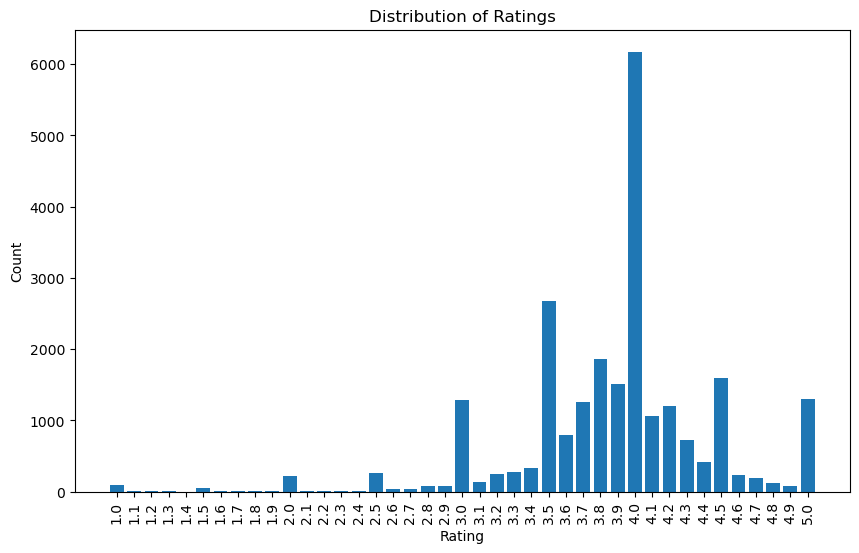

In [26]:
## plot distribution of review ratings
rating_counts = filtered_df.rating.value_counts().sort_index()

plt.figure(figsize=(10, 6))
plt.bar(rating_counts.index, rating_counts.values)
plt.xlabel('Rating')
plt.ylabel('Count')
plt.title('Distribution of Ratings')
plt.xticks(rotation=90)  # Rotate x-axis labels if they are too crowded
plt.show()

In [27]:
# save to csv
filtered_df.to_csv("../data/filtered_vivino_user_reviews.csv", index=False)